In [9]:
import pandas as pd

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("All libraries imported successfully!")


All libraries imported successfully!


In [11]:
df = pd.read_csv(r"C:\Users\siddu\Downloads\citydata.csv")

print("Dataset loaded successfully!")
display(df.head())

Dataset loaded successfully!


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,01-01-2015,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,02-01-2015,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,03-01-2015,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,04-01-2015,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,05-01-2015,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


In [12]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:", df.duplicated().sum())

print("\nTotal Cities:", df["City"].nunique())

Dataset Shape: (29531, 16)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 29531 entries, 0 to 29530
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   City        29531 non-null  str    
 1   Date        29531 non-null  str    
 2   PM2.5       24933 non-null  float64
 3   PM10        18391 non-null  float64
 4   NO          25949 non-null  float64
 5   NO2         25946 non-null  float64
 6   NOx         25346 non-null  float64
 7   NH3         19203 non-null  float64
 8   CO          27472 non-null  float64
 9   SO2         25677 non-null  float64
 10  O3          25509 non-null  float64
 11  Benzene     23908 non-null  float64
 12  Toluene     21490 non-null  float64
 13  Xylene      11422 non-null  float64
 14  AQI         24850 non-null  float64
 15  AQI_Bucket  24850 non-null  str    
dtypes: float64(13), str(3)
memory usage: 3.6 MB

Missing Values:
City              0
Date              0
PM2.5    

In [13]:
# Convert Date column into datetime format
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

In [14]:
# Remove invalid dates
df = df.dropna(subset=["Date"])
# Remove duplicate records
df = df.drop_duplicates()

In [16]:
# Sort data by date
df = df.sort_values("Date").reset_index(drop=True)
print("Date conversion and cleaning completed!")
print("Date range:", df["Date"].min(), "to", df["Date"].max())

Date conversion and cleaning completed!
Date range: 2015-01-01 00:00:00 to 2020-12-06 00:00:00


In [28]:
 # Extract month, year and season
df["Month"] = df["Date"].dt.month
df["Year"] = df["Date"].dt.year

def get_season(month):
    if month in [12, 1, 2]:
        return "Winter"
    elif month in [3, 4, 5]:
        return "Summer"
    elif month in [6, 7, 8, 9]:
        return "Monsoon"
    else:
        return "Post-Monsoon"

df["Season"] = df["Month"].apply(get_season)

display(df[["City", "Date", "Month", "Year", "Season"]].head())

Time features created successfully!


In [18]:
print("Total records:", len(df))

print("Available PM2.5 records:", df["PM2.5"].notna().sum())

print("Missing PM2.5 records:", df["PM2.5"].isna().sum())

print("PM2.5 availability percentage:",
      round(df["PM2.5"].notna().mean() * 100, 2), "%")

Total records: 11590
Available PM2.5 records: 9761
Missing PM2.5 records: 1829
PM2.5 availability percentage: 84.22 %


In [19]:
print("Current dataset shape:", df.shape)

print("Unique cities:", df["City"].nunique())

print("\nRecords per city:")
print(df["City"].value_counts())

print("\nDate range:")
print(df["Date"].min(), "to", df["Date"].max())

Current dataset shape: (11590, 19)
Unique cities: 26

Records per city:
City
Ahmedabad             793
Chennai               793
Delhi                 793
Lucknow               793
Mumbai                793
Bengaluru             793
Hyderabad             790
Patna                 733
Gurugram              661
Visakhapatnam         577
Amritsar              481
Jorapokhar            457
Jaipur                433
Thiruvananthapuram    433
Amaravati             373
Brajrajnagar          367
Talcher               361
Kolkata               316
Guwahati              193
Coimbatore            146
Shillong              121
Chandigarh            120
Bhopal                109
Ernakulam              61
Kochi                  61
Aizawl                 39
Name: count, dtype: int64

Date range:
2015-01-01 00:00:00 to 2020-12-06 00:00:00


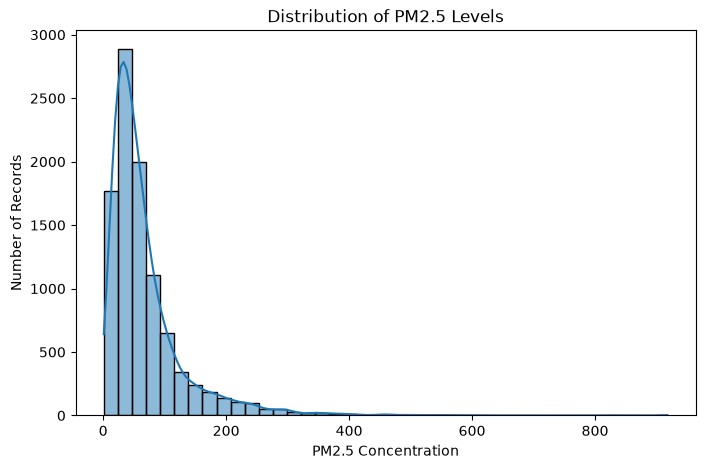

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.histplot(df["PM2.5"].dropna(), bins=40, kde=True)

plt.title("Distribution of PM2.5 Levels")
plt.xlabel("PM2.5 Concentration")
plt.ylabel("Number of Records")

plt.show()

City
Gurugram              123.195050
Delhi                 122.958182
Patna                 122.576601
Lucknow               109.372853
Ahmedabad              68.957956
Brajrajnagar           66.223179
Jorapokhar             64.761620
Kolkata                64.309966
Guwahati               62.318860
Talcher                60.880070
Amritsar               58.812048
Jaipur                 55.756859
Chennai                49.995518
Bhopal                 49.286699
Visakhapatnam          47.297060
Hyderabad              45.577888
Shillong               43.778043
Chandigarh             42.099375
Amaravati              39.257379
Bengaluru              35.259749
Mumbai                 34.705081
Coimbatore             28.836042
Kochi                  27.911148
Thiruvananthapuram     27.372370
Ernakulam              22.820328
Aizawl                 16.875789
Name: PM2.5, dtype: float64


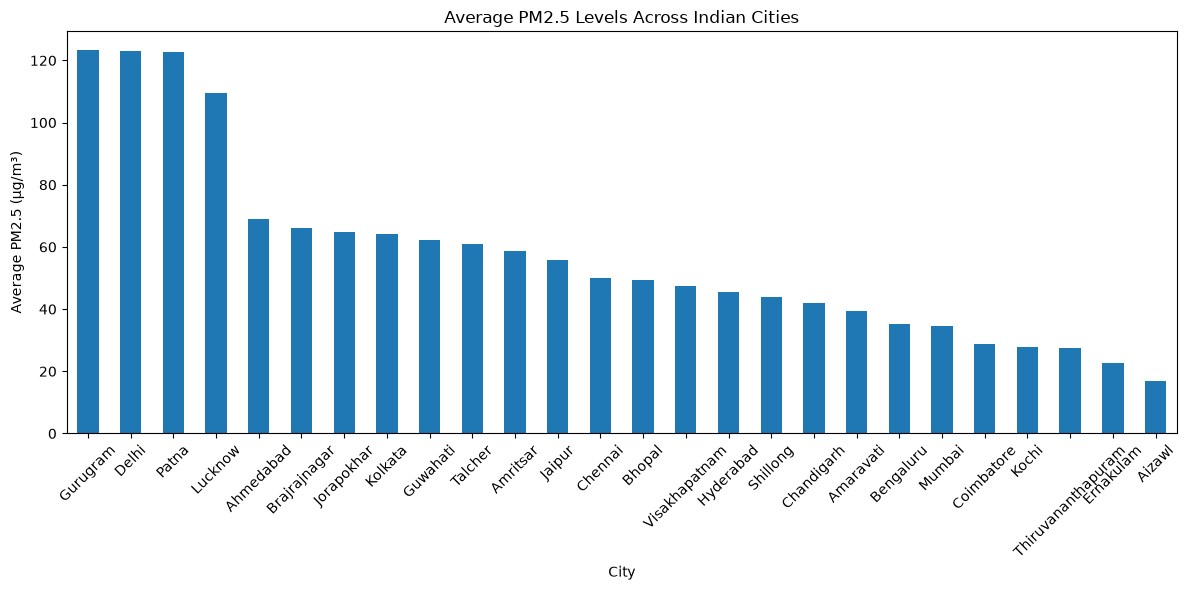

In [21]:
# Calculate average PM2.5 for each city
city_pollution = df.groupby("City")["PM2.5"].mean()

# Sort from highest to lowest
city_pollution = city_pollution.sort_values(ascending=False)

# Display results
print(city_pollution)

# Create bar chart
plt.figure(figsize=(12, 6))

city_pollution.plot(kind="bar")

plt.title("Average PM2.5 Levels Across Indian Cities")
plt.xlabel("City")
plt.ylabel("Average PM2.5 (µg/m³)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [22]:
# Calculate average PM2.5 for each season
season_pollution = df.groupby("Season")["PM2.5"].mean()

print("Average PM2.5 by Season:")
print(season_pollution)

Average PM2.5 by Season:
Season
Monsoon         68.243543
Post-Monsoon    68.546753
Summer          68.806178
Winter          68.834667
Name: PM2.5, dtype: float64


In [24]:
highest_season = season_pollution.idxmax()
highest_value = season_pollution.max()

print("Highest pollution season:", highest_season)
print("Average PM2.5:", round(highest_value, 2), "µg/m³")

Highest pollution season: Winter
Average PM2.5: 68.83 µg/m³


In [25]:
# Select numerical pollutant columns
pollutants = ["PM2.5", "PM10", "NO", "NO2", "NOx",
              "NH3", "CO", "SO2", "O3"]

correlation = df[pollutants].corr()

print("Pollutant Correlation:")
display(correlation)

Pollutant Correlation:


,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3
PM2.5,1.000000,0.847901,0.438036,0.349193,0.434270,0.281041,0.088913,0.126061,0.152378
PM10,0.847901,1.000000,0.516301,0.458002,0.534404,0.379519,0.112196,0.256670,0.239087
NO,0.438036,0.516301,1.000000,0.493603,0.796288,0.197894,0.187540,0.159490,0.024698
NO2,0.349193,0.458002,0.493603,1.000000,0.637467,0.246365,0.360043,0.379658,0.272410
NOx,0.434270,0.534404,0.796288,0.637467,1.000000,0.173013,0.212017,0.225025,0.095004
NH3,0.281041,0.379519,0.197894,0.246365,0.173013,1.000000,0.099019,-0.035168,0.097143
CO,0.088913,0.112196,0.187540,0.360043,0.212017,0.099019,1.000000,0.484871,0.032416
SO2,0.126061,0.256670,0.159490,0.379658,0.225025,-0.035168,0.484871,1.000000,0.148294
O3,0.152378,0.239087,0.024698,0.272410,0.095004,0.097143,0.032416,0.148294,1.000000


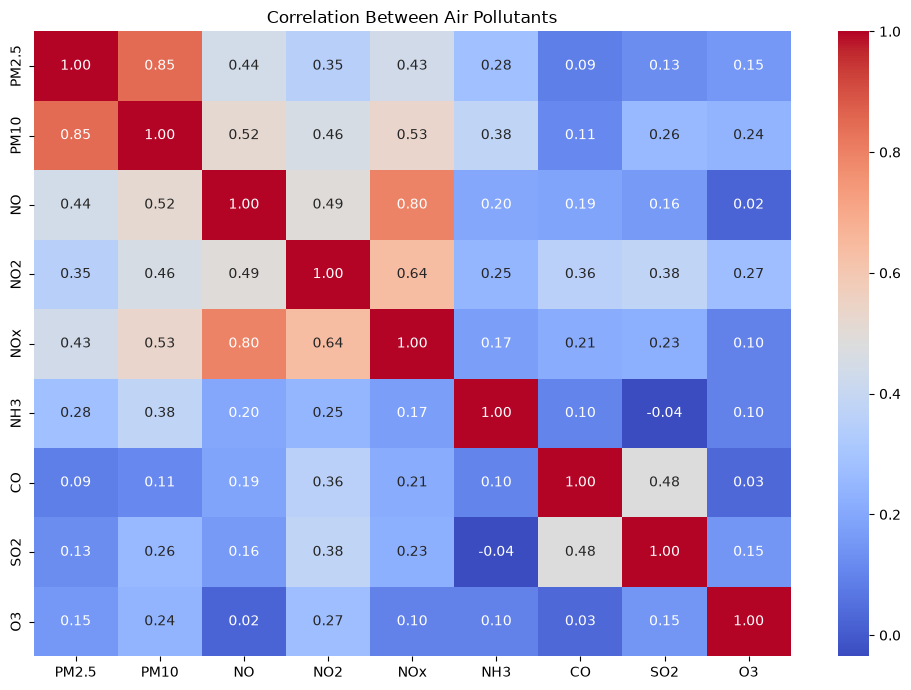

In [26]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Air Pollutants")
plt.tight_layout()
plt.show()

In [27]:
# Reload original dataset
original_df = pd.read_csv(r"C:\Users\siddu\Downloads\citydata.csv")

print("Original records:", len(original_df))
print("Current records:", len(df))

print("\nOriginal date sample:")
print(original_df["Date"].head(10).tolist())

print("\nCurrent date range:")
print(df["Date"].min(), "to", df["Date"].max())

Original records: 29531
Current records: 11590

Original date sample:
['01-01-2015', '02-01-2015', '03-01-2015', '04-01-2015', '05-01-2015', '06-01-2015', '07-01-2015', '08-01-2015', '09-01-2015', '10-01-2015']

Current date range:
2015-01-01 00:00:00 to 2020-12-06 00:00:00


In [29]:
# Extract month and year
df["Month"] = df["Date"].dt.month
df["Year"] = df["Date"].dt.year

# Assign seasons
def get_season(month):
    if month in [12, 1, 2]:
        return "Winter"
    elif month in [3, 4, 5]:
        return "Summer"
    elif month in [6, 7, 8, 9]:
        return "Monsoon"
    else:
        return "Post-Monsoon"

df["Season"] = df["Month"].apply(get_season)

print("Time features created successfully!")

Time features created successfully!


In [30]:
print("Total records:", len(df))
print("Total cities:", df["City"].nunique())

print("\nPM2.5 available:", df["PM2.5"].notna().sum())

print("\nMissing dates:", df["Date"].isnull().sum())

print("\nRecords per year:")
print(df["Year"].value_counts().sort_index())

Total records: 11590
Total cities: 26

PM2.5 available: 9761

Missing dates: 0

Records per year:
Year
2015    1101
2016    1368
2017    1818
2018    2547
2019    2916
2020    1840
Name: count, dtype: int64


In [32]:
import pandas as pd

# Reload original dataset
df = pd.read_csv(r"C:\Users\siddu\Downloads\citydata.csv")

print("Original records:", len(df))

# Correct date format
df["Date"] = pd.to_datetime(
    df["Date"],
    format="%d-%m-%Y",
    errors="coerce"
)

print("Invalid dates:", df["Date"].isna().sum())

# Remove only invalid dates
df = df.dropna(subset=["Date"])

# Remove duplicates
df = df.drop_duplicates()

# Sort records
df = df.sort_values("Date").reset_index(drop=True)

# Create time features
df["Month"] = df["Date"].dt.month
df["Year"] = df["Date"].dt.year

print("\nFinal dataset shape:", df.shape)
print("Total cities:", df["City"].nunique())
print("PM2.5 available:", df["PM2.5"].notna().sum())

Original records: 29531
Invalid dates: 0

Final dataset shape: (29531, 18)
Total cities: 26
PM2.5 available: 24933


In [ ]:
#machine learning 

In [37]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [40]:
# Select input features
features = [
    "City", "Month", "PM10", "NO", "NO2",
    "NOx", "NH3", "CO", "SO2", "O3"
]


In [41]:
# Input and target
X = df[features]
y = df["PM2.5"]
 

In [42]:
# Remove records without target values
valid = y.notna()
X = X[valid]
y = y[valid]

In [43]:
# Split data chronologically
dates = df.loc[valid, "Date"]
split_date = dates.quantile(0.80)

train_mask = dates < split_date

X_train = X[train_mask]
X_test = X[~train_mask]
y_train = y[train_mask]
y_test = y[~train_mask]

In [44]:
# Handle missing values and city names
preprocessor = ColumnTransformer([
    ("numeric", SimpleImputer(strategy="median"), features[1:]),
    ("city", OneHotEncoder(handle_unknown="ignore"), ["City"])
])

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)
print("Data preparation successful!")

Training data: (19926, 10)
Testing data: (5007, 10)
Data preparation successful!


In [46]:
#Linear regression model 
linear_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

linear_model.fit(X_train, y_train)

linear_predictions = linear_model.predict(X_test)

print("Linear Regression training completed!")

Linear Regression training completed!


In [47]:
 # Create Random Forest model
random_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

# Train the model
random_model.fit(X_train, y_train)

# Make predictions
random_predictions = random_model.predict(X_test)

print("Random Forest training completed!")

Random Forest training completed!


In [48]:
 # Store model results
results = []

models = {
    "Linear Regression": linear_predictions,
    "Random Forest": random_predictions
}

for name, predictions in models.items():

    mae = mean_absolute_error(y_test, predictions)

    rmse = np.sqrt(mean_squared_error(y_test, predictions))

    r2 = r2_score(y_test, predictions)

    results.append({
        "Model": name,
        "MAE": round(mae, 2),
        "RMSE": round(rmse, 2),
        "R2 Score": round(r2, 3)
    })

results_df = pd.DataFrame(results)

display(results_df)

,Model,MAE,RMSE,R2 Score
0,Linear Regression,22.28,35.61,0.234
1,Random Forest,13.92,24.74,0.630


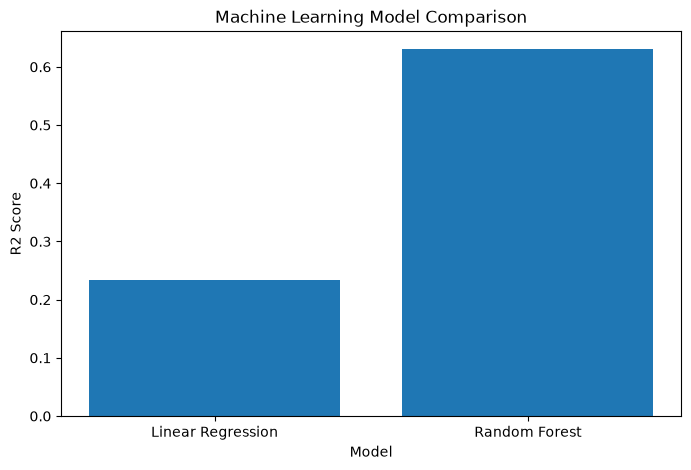

In [50]:
plt.figure(figsize=(8, 5))

plt.bar(results_df["Model"], results_df["R2 Score"])

plt.title("Machine Learning Model Comparison")
plt.ylabel("R2 Score")
plt.xlabel("Model")

plt.show()

In [51]:
comparison = pd.DataFrame({
    "Actual PM2.5": y_test.values,
    "Predicted PM2.5": random_predictions
})

display(comparison.head(10))

,Actual PM2.5,Predicted PM2.5
0,30.38,31.5930
1,211.92,238.5771
2,78.95,72.2498
3,173.25,141.4952
4,82.73,77.7206
5,86.08,90.2140
6,200.33,186.6063
7,112.06,90.0831
8,17.78,28.5909
9,56.61,71.9491


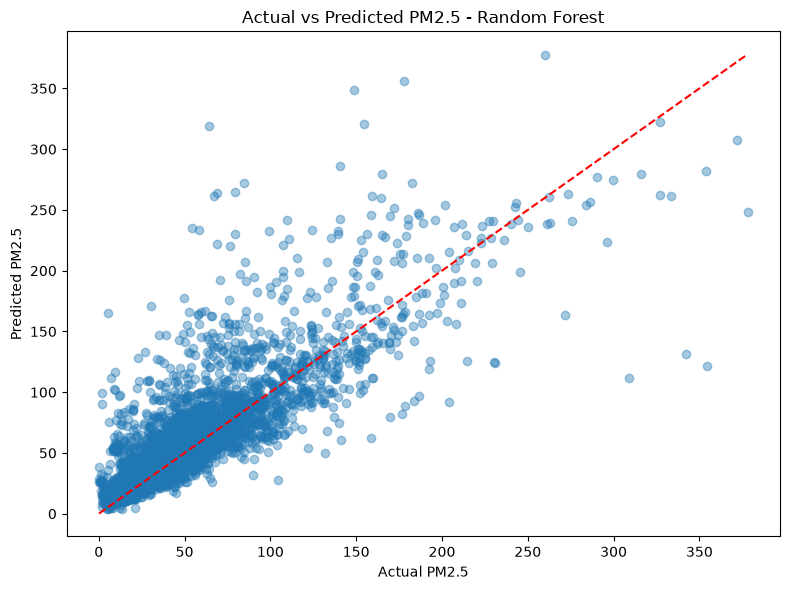

In [52]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, random_predictions, alpha=0.4)

plt.xlabel("Actual PM2.5")
plt.ylabel("Predicted PM2.5")
plt.title("Actual vs Predicted PM2.5 - Random Forest")

# Perfect prediction reference line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--"
)

plt.tight_layout()
plt.show()

In [53]:
display(results_df)

,Model,MAE,RMSE,R2 Score
0,Linear Regression,22.28,35.61,0.234
1,Random Forest,13.92,24.74,0.630


In [54]:
# Create a comparison between actual and predicted PM2.5 values

prediction_comparison = pd.DataFrame({
    "Actual PM2.5": y_test.values,
    "Predicted PM2.5": random_predictions
})

prediction_comparison["Difference"] = (
    prediction_comparison["Actual PM2.5"] -
    prediction_comparison["Predicted PM2.5"]
).abs()

display(prediction_comparison.head(10).round(2))

,Actual PM2.5,Predicted PM2.5,Difference
0,30.38,31.59,1.21
1,211.92,238.58,26.66
2,78.95,72.25,6.70
3,173.25,141.50,31.75
4,82.73,77.72,5.01
5,86.08,90.21,4.13
6,200.33,186.61,13.72
7,112.06,90.08,21.98
8,17.78,28.59,10.81
9,56.61,71.95,15.34
